# Predictors

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
BASE = Path.cwd()
if not (BASE / "evidence").exists():
    BASE = BASE / "notebooks" 
assert (BASE / "evidence").is_dir(), "Open from the project root or notebooks."
EVIDENCE = BASE / "evidence"
def read_json(name):
    return json.loads((EVIDENCE / name).read_text(encoding="utf-8-sig"))
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})


## Input groups
The original model uses 93 inputs, expanded to 238 encoded columns. Inputs are not learned parameters. The main table below groups them; the full dictionary at the end names every input and explains its type, missingness and observed relationship.

Group,Inputs
Derived weather interactions,5
Geographic environment,12
Past recorded pest/service history,13
"Service, package and premises",16
Weather before service,19
Pest category and indicators,28


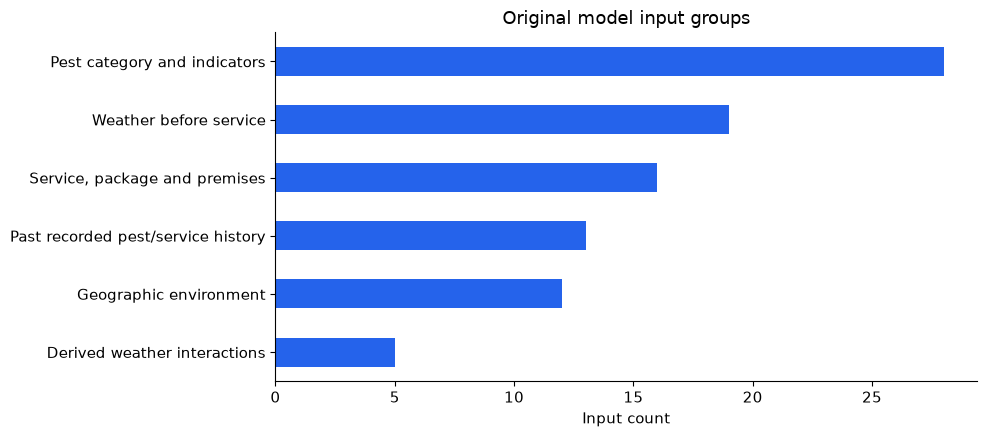

In [2]:
variables = pd.read_csv(EVIDENCE / "variables_plain_english.csv")
assert len(variables) == 93
groups = variables.groupby("Group").size().sort_values()
display(groups.rename("Inputs").reset_index())
groups.plot.barh(color="#2563eb")
plt.xlabel("Input count"); plt.ylabel(""); plt.title("Original model input groups")
plt.tight_layout(); plt.show()

## Observed relationships
These are pairwise correlations on earlier development data only. A positive value means higher observed input values tend to appear with more return labels; a negative value means the opposite. Correlation does not establish causality, individual significance or benefit when added to the model.

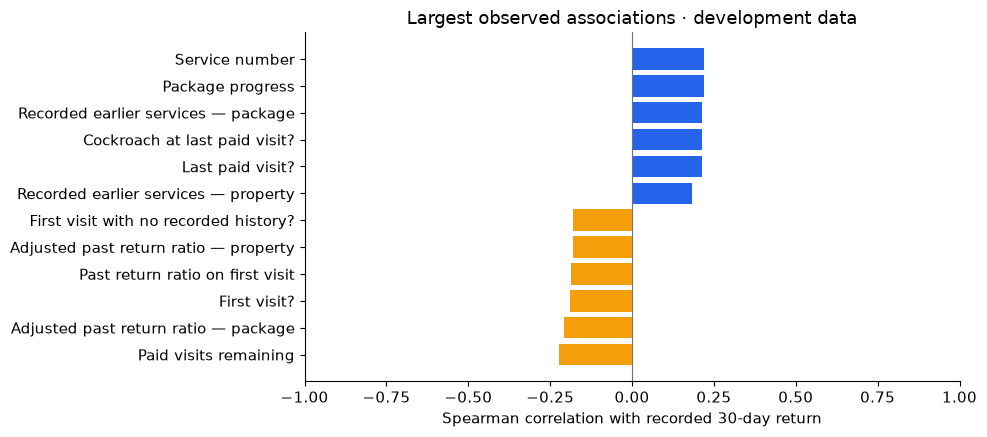

In [3]:
association = pd.read_csv(EVIDENCE / "numeric_associations.csv")
names = variables.set_index("Technical field")["Variable"].to_dict()
association["Input"] = association["feature"].map(names).fillna(association["feature"])
shown = association.dropna(subset=["spearman_rho"]).assign(magnitude=lambda d:d.spearman_rho.abs()).nlargest(12,"magnitude").sort_values("spearman_rho")
plt.barh(shown.Input, shown.spearman_rho, color=["#2563eb" if x>=0 else "#f59e0b" for x in shown.spearman_rho])
plt.axvline(0,color="#64748b",lw=.8); plt.xlim(-1,1)
plt.xlabel("Spearman correlation with recorded 30-day return"); plt.title("Largest observed associations · development data")
plt.tight_layout(); plt.show()

## Did removing inputs help?
The group-removal table compares the same chronological validation periods. AP measures probability ranking; Brier measures probability error (lower is better). Neither is a causal effect. Individual removal is exploratory: selecting many changes from one validation set can overfit it. No new input is automatically added to the frozen model.

In [4]:
display(pd.read_csv(EVIDENCE / "group_decisions.csv").round(4))
removal = pd.read_csv(EVIDENCE / "individual_removal_decisions.csv")
print("Individual-removal records:", len(removal))
display(removal)

variant,mean_AP,mean_Brier,mean_F1,mean_accuracy,AP_change_vs_full,Brier_change_vs_full,folds_improved_both,decision
All 93 inputs,0.2483,0.0831,0.2775,0.8448,0.0000,0.0000,0,Reference
Without Derived weather interactions,0.2455,0.0827,0.2896,0.8558,-0.0028,-0.0004,1,No consistent evidence to remove this whole group
Without Geographic environment,0.2592,0.0832,0.2613,0.8493,0.0109,0.0001,0,No consistent evidence to remove this whole group
Without Past recorded pest/service history,0.2490,0.0822,0.2316,0.8362,0.0007,-0.0009,1,No consistent evidence to remove this whole group
Without Pest category and indicators,0.2325,0.0829,0.2469,0.8056,-0.0158,-0.0002,0,No consistent evidence to remove this whole group
"Without Service, package and premises",0.2395,0.0842,0.2399,0.8399,-0.0088,0.0011,0,No consistent evidence to remove this whole group
Without Weather before service,0.2311,0.0828,0.2657,0.8572,-0.0173,-0.0003,0,No consistent evidence to remove this whole group


Technical field,Variable,Mean AP change after removal,Mean Brier change after removal,Folds improved both,Decision
anchor_is_final,Last paid visit?,-0.005974,-0.000571,0,Mixed evidence: no automatic removal
anchor_is_first,First visit?,0.006978,-0.000671,1,Mixed evidence: no automatic removal
anchor_is_mixed_pest,Multiple pest types?,-0.007264,-0.000336,0,Mixed evidence: no automatic removal
anchor_is_single_service,One-visit package?,-0.003518,-0.000623,0,Mixed evidence: no automatic removal
anchor_month_cos,Service month — seasonal input B,-0.003018,0.000169,1,Mixed evidence: no automatic removal
anchor_month_sin,Service month — seasonal input A,0.004318,-0.000341,1,Mixed evidence: no automatic removal
anchor_remaining_services,Paid visits remaining,-0.001925,-0.000506,1,Mixed evidence: no automatic removal
anchor_service_progress,Package progress,-0.003477,-0.000448,0,Mixed evidence: no automatic removal
calendar_pest_text_category,Pest mentioned in appointment,0.000981,-0.000545,1,Mixed evidence: no automatic removal
calendar_service_method_category,Treatment method,-0.008706,-0.000268,0,Mixed evidence: no automatic removal


Individual-removal records: 93


## All original inputs
The table gives the exact technical field for tracing the scripts alongside the reader-facing name. Building age and complete online building pest history are unavailable. Neighbourhood settlement age, holiday, rainfall-between-visit, food and facility experiments belong to separate candidate studies; their results are in chapter 7.

In [5]:
for group_name, group in variables.groupby("Group", sort=True):
    print(group_name)
    display(group[["Variable", "What it means", "Type", "Missing (%)", "Observed relationship", "Technical field"]].reset_index(drop=True))

Variable,What it means,Type,Missing (%),Observed relationship,Technical field
Rain combined with drain proximity,14-day rain / (1 + drainage distance in kilometres).,numerical,18.6,Higher values linked to more returns (correlation +0.026). Very small relationship.,drainage_rain_interaction
Rain before first visit,14-day rain on first visits; zero on other stages.,numerical,0.0,Higher values linked to fewer returns (correlation -0.179).,first_service_rain_14d
Rain with multiple pest types,14-day rain for mixed-pest records; zero otherwise.,numerical,0.0,Higher values linked to fewer returns (correlation -0.061). Very small relationship.,mixed_pest_rain_14d
Rain combined with soil moisture,14-day rain multiplied by 7-day average surface soil moisture.,numerical,0.0,Higher values linked to more returns (correlation +0.011). Very small relationship.,rain_soil_interaction
Rain combined with waterway proximity,14-day rain / (1 + waterway distance in kilometres). Larger with more rain or closer water.,numerical,18.6,Higher values linked to more returns (correlation +0.023). Very small relationship.,water_rain_interaction


Variable,What it means,Type,Missing (%),Observed relationship,Technical field
Elevation (metres),Ground height above sea level.,numerical,18.6,Higher values linked to fewer returns (correlation -0.020). Very small relationship.,elevation_m
Distance to mapped drainage (metres),Distance to the nearest mapped drainage; map coverage may be incomplete.,numerical,18.6,Higher values linked to fewer returns (correlation -0.004). Very small relationship.,hotosm_nearest_drainage_m
Distance to mapped flowing water (metres),Distance to the nearest mapped flowing water; map coverage may be incomplete.,numerical,18.6,Higher values linked to more returns (correlation +0.041). Very small relationship.,hotosm_nearest_flowing_water_m
Distance to mapped standing water (metres),Distance to the nearest mapped standing water; map coverage may be incomplete.,numerical,18.6,Higher values linked to fewer returns (correlation -0.017). Very small relationship.,hotosm_nearest_standing_water_m
Distance to mapped waterway (metres),Distance to the nearest mapped waterway; map coverage may be incomplete.,numerical,18.6,Higher values linked to more returns (correlation +0.010). Very small relationship.,hotosm_nearest_waterway_m
Water features within 1km,Count of mapped water features within 1km of the location.,numerical,18.6,Higher values linked to fewer returns (correlation -0.008). Very small relationship.,hotosm_water_features_1km
Water features within 2km,Count of mapped water features within 2km of the location.,numerical,18.6,Higher values linked to fewer returns (correlation -0.014). Very small relationship.,hotosm_water_features_2km
Water features within 500m,Count of mapped water features within 500m of the location.,numerical,18.6,Higher values linked to more returns (correlation +0.002). Very small relationship.,hotosm_water_features_500m
Nearby height variation (metres),Terrain-height variation within 500 metres.,numerical,18.6,Higher values linked to fewer returns (correlation -0.020). Very small relationship.,local_relief_500m_m
Transformed distance to waterway,Logarithm of 1 + waterway distance in metres; reduces the influence of very large distances.,numerical,18.6,Higher values linked to more returns (correlation +0.010). Very small relationship.,log1p_waterway_distance


Variable,What it means,Type,Missing (%),Observed relationship,Technical field
Days since last recorded return,Time since the last corrective return recorded at this property.,numerical,97.1,Higher values linked to fewer returns (correlation -0.162).,days_since_prior_property_claim
First visit with no recorded history?,1 for a first paid visit with no earlier recorded property service.,binary indicator,0.0,Higher values linked to fewer returns (correlation -0.181).,first_service_no_property_history
Past return ratio on first visit,Adjusted property return ratio on first visits; zero on other stages.,numerical,0.0,Higher values linked to fewer returns (correlation -0.188).,first_service_prior_property_return_rate
Past return ratio for multiple pests,Adjusted property return ratio for mixed-pest records; zero otherwise.,numerical,0.0,Higher values linked to fewer returns (correlation -0.063). Very small relationship.,mixed_pest_prior_property_return_rate
Recorded returns in previous 90 days — area,Count of earlier recorded corrective return visits for this area in the previous 90 days.,numerical,0.0,Higher values linked to more returns (correlation +0.030). Very small relationship.,prior_area_claims_90d
Recorded services in previous 90 days — area,Count of earlier recorded service events for this area in the previous 90 days.,numerical,0.0,Higher values linked to fewer returns (correlation -0.011). Very small relationship.,prior_area_services_90d
Adjusted past return ratio — package,"(Earlier package returns + 1) / (earlier package services + 10). Adjusted ratio, not a literal infestation rate.",numerical,0.0,Higher values linked to fewer returns (correlation -0.206).,prior_package_return_rate_smoothed
Recorded earlier services — package,Count of earlier recorded service events for this package.,numerical,0.0,Higher values linked to more returns (correlation +0.214).,prior_package_service_events
Recorded earlier returns — package,Count of earlier recorded corrective return visits for this package.,numerical,0.0,Higher values linked to more returns (correlation +0.022). Very small relationship.,prior_package_warranty_claims
Recorded returns in previous 90 days — property,Count of earlier recorded corrective return visits for this property in the previous 90 days.,numerical,0.0,Higher values linked to more returns (correlation +0.031). Very small relationship.,prior_property_claims_90d


Variable,What it means,Type,Missing (%),Observed relationship,Technical field
Multiple pest types?,1 when at least two known pest types are recorded.,binary indicator,0.0,Higher values linked to fewer returns (correlation -0.062). Very small relationship.,anchor_is_mixed_pest
Pest mentioned in appointment,Category extracted from Calendar pest text.,categorical,0.0,Depends on category; no single up/down direction.,calendar_pest_text_category
Ant at last paid visit?,1 when ant is recorded AND this is the last paid visit; 0 otherwise.,binary indicator,0.0,Higher values linked to more returns (correlation +0.006). Very small relationship.,final_pest_ant
Bed Bug at last paid visit?,1 when bed bug is recorded AND this is the last paid visit; 0 otherwise.,binary indicator,0.0,Higher values linked to fewer returns (correlation -0.009). Very small relationship.,final_pest_bed_bug
Cockroach at last paid visit?,1 when cockroach is recorded AND this is the last paid visit; 0 otherwise.,binary indicator,0.0,Higher values linked to more returns (correlation +0.213).,final_pest_cockroach
Fly at last paid visit?,1 when fly is recorded AND this is the last paid visit; 0 otherwise.,binary indicator,0.0,Higher values linked to fewer returns (correlation -0.009). Very small relationship.,final_pest_fly
Mosquito at last paid visit?,1 when mosquito is recorded AND this is the last paid visit; 0 otherwise.,binary indicator,0.0,Cannot measure: no variation or insufficient values.,final_pest_mosquito
Rodent at last paid visit?,1 when rodent is recorded AND this is the last paid visit; 0 otherwise.,binary indicator,0.0,Higher values linked to fewer returns (correlation -0.021). Very small relationship.,final_pest_rodent
Termite at last paid visit?,1 when termite is recorded AND this is the last paid visit; 0 otherwise.,binary indicator,0.0,Higher values linked to more returns (correlation +0.056). Very small relationship.,final_pest_termite
Ant at first paid visit?,1 when ant is recorded AND this is the first paid visit; 0 otherwise.,binary indicator,0.0,Higher values linked to fewer returns (correlation -0.062). Very small relationship.,first_pest_ant


Variable,What it means,Type,Missing (%),Observed relationship,Technical field
Last paid visit?,1 when this is the final recorded paid visit in the package.,binary indicator,0.0,Higher values linked to more returns (correlation +0.213).,anchor_is_final
First visit?,1 for the first paid visit; 0 otherwise.,binary indicator,0.0,Higher values linked to fewer returns (correlation -0.189).,anchor_is_first
One-visit package?,1 for a package containing one paid service.,binary indicator,0.0,Higher values linked to fewer returns (correlation -0.076). Very small relationship.,anchor_is_single_service
Service month — seasonal input B,Cosine of month; paired with input A. Neither alone means earlier or later months.,numerical,0.0,Higher values linked to more returns (correlation +0.064). Very small relationship.,anchor_month_cos
Service month — seasonal input A,Sine of month; used with input B so December and January are treated as neighbours.,numerical,0.0,Higher values linked to fewer returns (correlation -0.071). Very small relationship.,anchor_month_sin
Paid visits remaining,Package visits minus the current service number.,numerical,0.0,Higher values linked to fewer returns (correlation -0.223).,anchor_remaining_services
Package progress,Current service number divided by the number of package visits.,numerical,0.0,Higher values linked to more returns (correlation +0.218).,anchor_service_progress
Treatment method,Recorded treatment-method category from Calendar text.,categorical,0.0,Depends on category; no single up/down direction.,calendar_service_method_category
Days from sale to visit,Elapsed days between the sale and this service.,numerical,0.0,Higher values linked to more returns (correlation +0.104).,days_sale_to_anchor
Days since previous visit,Recorded gap since the previous service.,numerical,37.1,Higher values linked to fewer returns (correlation -0.127).,days_since_previous_service


Variable,What it means,Type,Missing (%),Observed relationship,Technical field
Days since rain,"Days since at least 1 mm of daily rain, capped at 30 days.",numerical,0.0,Higher values linked to fewer returns (correlation -0.039). Very small relationship.,days_since_last_rain_1mm_capped_30d
Days with at least 10 mm rain — previous 14 days,"Days with at least 10 mm rain measured before the service, across the previous 14 days.",numerical,0.0,Higher values linked to more returns (correlation +0.013). Very small relationship.,prior_14d_heavy_rain_days_10mm
Highest daily rain (mm) — previous 14 days,"Highest daily rain (mm) measured before the service, across the previous 14 days.",numerical,0.0,Higher values linked to more returns (correlation +0.005). Very small relationship.,prior_14d_max_daily_precipitation_mm
Total rain (mm) — previous 14 days,"Total rain (mm) measured before the service, across the previous 14 days.",numerical,0.0,Higher values linked to more returns (correlation +0.014). Very small relationship.,prior_14d_precipitation_mm
Days with at least 1 mm rain — previous 14 days,"Days with at least 1 mm rain measured before the service, across the previous 14 days.",numerical,0.0,Higher values linked to more returns (correlation +0.012). Very small relationship.,prior_14d_wet_days_1mm
Total rain (mm) — previous 1 days,"Total rain (mm) measured before the service, across the previous 1 days.",numerical,0.0,Higher values linked to more returns (correlation +0.024). Very small relationship.,prior_1d_precipitation_mm
Total rain (mm) — previous 30 days,"Total rain (mm) measured before the service, across the previous 30 days.",numerical,0.0,Higher values linked to more returns (correlation +0.009). Very small relationship.,prior_30d_precipitation_mm
Average relative humidity (%) — previous 30 days,"Average relative humidity (%) measured before the service, across the previous 30 days.",numerical,0.0,Higher values linked to more returns (correlation +0.003). Very small relationship.,prior_30d_relative_humidity_mean_pct
Average surface soil moisture (top 7 cm) — previous 30 days,"Average surface soil moisture (top 7 cm) measured before the service, across the previous 30 days.",numerical,0.0,Higher values linked to fewer returns (correlation -0.009). Very small relationship.,prior_30d_soil_moisture_0_to_7cm_mean
Average temperature (°C) — previous 30 days,"Average temperature (°C) measured before the service, across the previous 30 days.",numerical,0.0,Higher values linked to more returns (correlation +0.001). Very small relationship.,prior_30d_temperature_mean_c


Derived weather interactions
Geographic environment
Past recorded pest/service history
Pest category and indicators
Service, package and premises
Weather before service
